# Radiative shocks (Lowrie & Edwards 2008)

Steady grey non-equilibrium radiative shocks (Lowrie & Edwards 2008, Shock Waves 18, 129) with
the production clean scheme: Mach 2 (subcritical) and Mach 5 (supercritical), cgs, held in
their own frame. The notebook runs the suite tests `radshock` and `radshock_m5`
(`$ATHENAK/tests/vet_clean/run_tests.py --only ...`), plots the gas and radiation temperature
and the density against the semi-analytic profiles and prints the suite's PASS / FAIL line.

In [1]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt
ATHENAK = os.path.abspath(os.environ.get('ATHENAK', '../../athenak'))   # your athenak checkout
sys.path.insert(0, os.path.join(ATHENAK, 'tests/vet_clean/notebooks'))
import nbutil as nb                        # nb.suite, nb.verdict, nb.vett (readers), nb.rt (run_tests)

# the athena binary (a CPU build, default the one tests/vet_clean/run_tests.sh builds)
EXE = os.path.abspath(os.environ.get('ATHENA_EXE', os.path.join(ATHENAK, 'build_tests/src/athena')))
# where the runs go; a test whose run is already there is only loaded, not rerun
WORK = os.path.abspath(os.environ.get('VET_NB_WORKDIR', 'runs'))
THREADS = int(os.environ.get('VET_NB_THREADS', '4'))   # OpenMP threads per run
nb.style()
vett, rt = nb.vett, nb.rt
print('binary', os.path.relpath(EXE), '\nruns  ', os.path.relpath(WORK))

binary ../../athenak/build_tests/src/athena 
runs   runs


## Radiative shocks (Lowrie & Edwards 2008)

Steady grey radiative shocks in their own frame, Mach 2 (subcritical) and Mach 5
(supercritical), cgs; initialised from the semi-analytic profile (`ref/idort_radshock_m*.txt`,
grey non-equilibrium diffusion with P = E/3) and run for 2e-10 s on 256 cells with the
production closure (`idort.ipynb` shows the same shocks with `clean_closure = eddington`). Criterion: L1 of
rho and T_rad within 5 % of the reference values, every L1 below its bound (1-2 %), E > 0,
no `CLEAN WARNING`. Most of the ~1 % in T_rad is the closure: the reference assumes the
Eddington closure in the thin precursor, the scheme uses the variable Eddington tensor.

In [2]:
res = {T: nb.suite(T, EXE, WORK, THREADS) for T in ('radshock', 'radshock_m5')}

loading the existing run runs/radshock
loading the existing run runs/radshock_m5


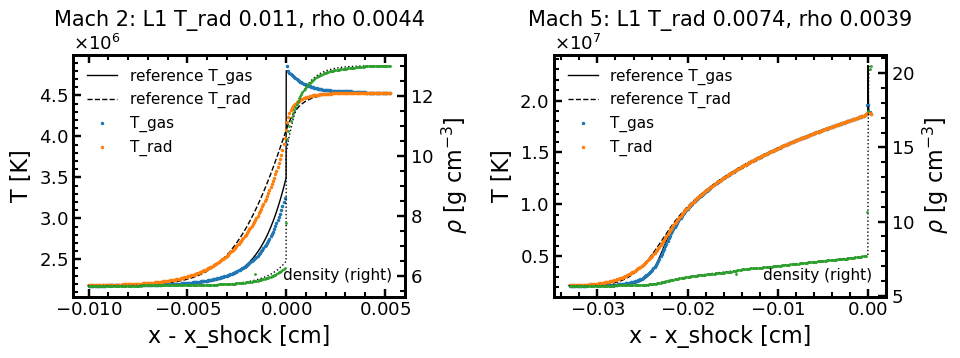

PASS radshock   criterion {"max": {"L1_rho": 0.01, "L1_v": 0.01, "L1_Tg": 0.015, "L1_Tr": 0.02}, "min": {"Emin": 1e-300}, "near": {"L1_rho": [0.004414, 0.05], "L1_Tr": [0.01069, 0.05]}, "equal": {"warnings": 0}}
PASS radshock_m5   criterion {"max": {"L1_rho": 0.01, "L1_v": 0.01, "L1_Tg": 0.015, "L1_Tr": 0.015}, "min": {"Emin": 1e-300}, "near": {"L1_rho": [0.00391, 0.05], "L1_Tr": [0.00744, 0.05]}, "equal": {"warnings": 0}}


In [3]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, (T, M) in zip(axs, (('radshock', 2), ('radshock_m5', 5))):
    d = os.path.join(WORK, T, 'run')
    r = np.loadtxt(os.path.join(nb.SUITE, 'ref', 'idort_radshock_m%d.txt' % M))
    p = vett.parse_deck_text(open(os.path.join(d, 'in.athinput')).read())
    xs, TUN, AR = (float(p[b][k]) for b, k in (('problem', 'vet_shock_xs'),
                                               ('problem', 'vet_shock_tunit'), ('rad_vet', 'arad')))
    m, h = vett.last_bin(d, 'vet'), vett.last_bin(d, 'hydro_w')
    x = vett.cell_centres(d)[0] - xs
    rho = rt.x1prof(h, 'dens')
    tg = (2/3)*rt.x1prof(h, 'eint')/rho/TUN
    tr = (rt.x1prof(m, 'vet_e')/AR)**0.25/TUN
    ax.plot(r[:, 0], r[:, 3], 'k-', lw=1, label='reference T_gas')
    ax.plot(r[:, 0], r[:, 4], 'k--', lw=1, label='reference T_rad')
    ax.plot(x, tg, 'C0.', ms=3, label='T_gas')
    ax.plot(x, tr, 'C1.', ms=3, label='T_rad')
    ax2 = ax.twinx()
    ax2.plot(r[:, 0], r[:, 1], 'k:', lw=1)
    ax2.plot(x, rho, 'C2.', ms=2, label='density (right)')
    ax2.set_ylabel(r'$\rho$ [g cm$^{-3}$]')
    ax.set(xlabel='x - x_shock [cm]', ylabel='T [K]',
           title='Mach %d: L1 T_rad %.2g, rho %.2g' % (M, res[T]['L1_Tr'], res[T]['L1_rho']))
    ax.legend(fontsize=11, loc='upper left'); ax2.legend(fontsize=11, loc='lower right')
plt.tight_layout(); plt.show()
for T in res:
    nb.verdict(T, res[T])